# EDA y Parte 1 — Calidad del aire del Valle de Aburra

Este notebook documenta el analisis exploratorio y los resultados del modelo
clasico (Naive Bayes Gaussiano implementado por el equipo), insumo del informe.

Reutiliza los modulos del proyecto (`src/`), ya cubiertos por pruebas.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src import data_loader as dl
from src import train
from src.naive_bayes import GaussianNaiveBayes
from sklearn.metrics import confusion_matrix

df, fuente = dl.load_data()
print('Fuente de datos:', fuente)
print('Filas:', len(df), '| Estaciones:', df['estacion'].nunique())
df.head()

Fuente de datos: csv
Filas: 4380 | Estaciones: 6


,fecha,estacion,pm25,temperatura,viento,precipitacion,lat,lon
0,2024-01-01,Medellin-Centro,22.9,21.6,2.43,0.0,6.2518,-75.5636
1,2024-01-02,Medellin-Centro,29.6,22.1,2.51,0.0,6.2518,-75.5636
2,2024-01-03,Medellin-Centro,29.1,22.2,1.40,2.6,6.2518,-75.5636
3,2024-01-04,Medellin-Centro,29.8,21.1,2.35,2.4,6.2518,-75.5636
4,2024-01-05,Medellin-Centro,31.4,22.7,2.08,0.0,6.2518,-75.5636


## 1. Distribucion del PM2.5 por estacion

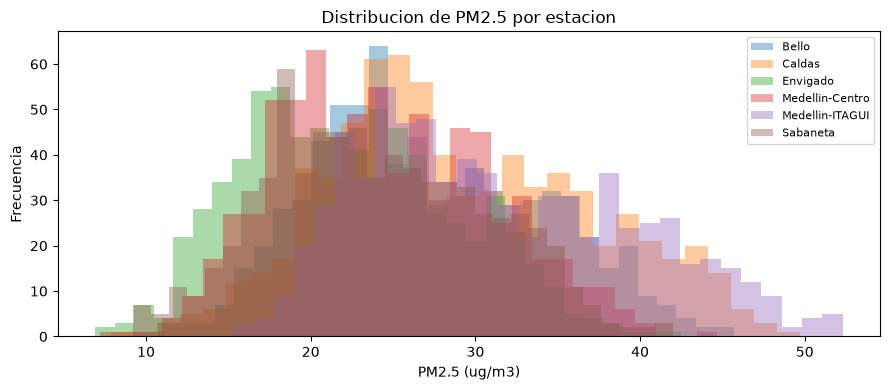

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
for est, g in df.groupby('estacion'):
    ax.hist(g['pm25'], bins=30, alpha=0.4, label=est)
ax.set_xlabel('PM2.5 (ug/m3)')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribucion de PM2.5 por estacion')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Serie de tiempo y estacionalidad

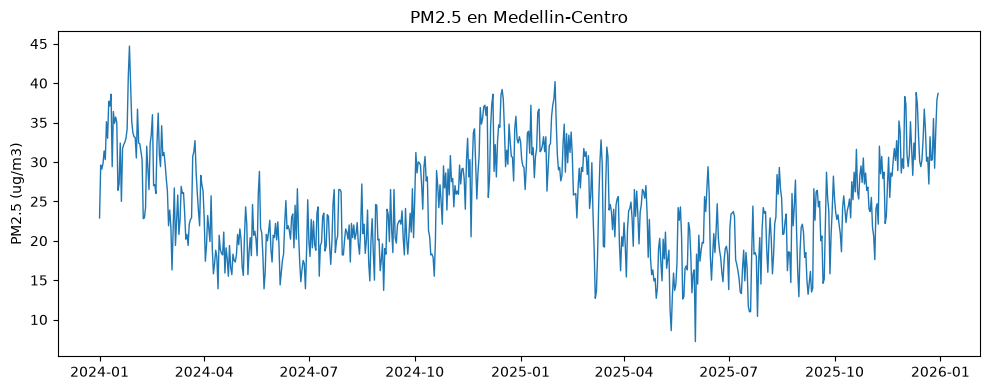

In [3]:
est = df['estacion'].unique()[0]
sub = df[df['estacion'] == est].sort_values('fecha')
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sub['fecha'], sub['pm25'], linewidth=1)
ax.set_title(f'PM2.5 en {est}')
ax.set_ylabel('PM2.5 (ug/m3)')
plt.tight_layout()
plt.show()

## 3. Relacion con la meteorologia

Correlacion entre PM2.5 y las variables meteorologicas (viento y lluvia suelen
limpiar el aire).

In [4]:
cols = ['pm25', 'temperatura', 'viento', 'precipitacion']
df[cols].corr()['pm25']

pm25             1.000000
temperatura      0.020799
viento          -0.117464
precipitacion   -0.147252
Name: pm25, dtype: float64

## 4. Entrenamiento del Naive Bayes y metricas vs lineas base

In [5]:
salida = train.entrenar_y_evaluar()
print('Train:', salida['n_train'], '| Test:', salida['n_test'])
print('Fecha de corte temporal:', salida['fecha_corte'])
print()
for r in salida['resultados']:
    print(f"{r.nombre:<40} accuracy={r.accuracy:.4f}  f1_macro={r.f1_macro:.4f}")

Train: 3498 | Test: 876
Fecha de corte temporal: 2025-08-06 00:00:00

Naive Bayes (propio)                     accuracy=0.9030  f1_macro=0.6003
Baseline: clase mayoritaria              accuracy=0.8311  f1_macro=0.3026
Baseline: persistencia (mañana=hoy)      accuracy=0.8995  f1_macro=0.5989


## 5. Matriz de confusion del Naive Bayes

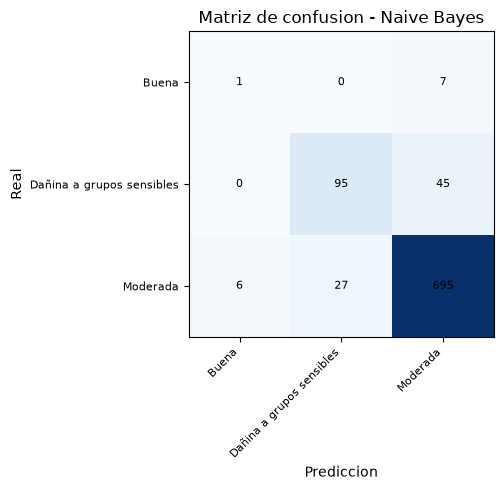

In [6]:
feats = dl.build_features(df)
tr, te, _ = train.split_temporal(feats)
nb = GaussianNaiveBayes().fit(tr[dl.FEATURES].to_numpy(), tr['objetivo'].to_numpy())
pred = nb.predict(te[dl.FEATURES].to_numpy())
clases = sorted(set(te['objetivo']))
cm = confusion_matrix(te['objetivo'], pred, labels=clases)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(clases)))
ax.set_yticks(range(len(clases)))
ax.set_xticklabels(clases, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(clases, fontsize=8)
ax.set_xlabel('Prediccion')
ax.set_ylabel('Real')
ax.set_title('Matriz de confusion - Naive Bayes')
for i in range(len(clases)):
    for j in range(len(clases)):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8)
plt.tight_layout()
plt.show()

## Conclusiones

- El Naive Bayes propio supera a las lineas base (clase mayoritaria y
  persistencia) en accuracy y F1 macro.
- Las clases estan desbalanceadas (predominan dias de buena/moderada calidad),
  lo que baja el F1 macro: es una limitacion a documentar.
- El viento y la lluvia correlacionan negativamente con el PM2.5, coherente con
  su efecto de dispersion/lavado.